In [1]:
import pandas as pd
import numpy as np
import joblib
import os
import sys
from pathlib import Path
# Ajoute la racine du projet à Python (marche que le notebook soit à la racine ou dans notebooks/)
root = Path.cwd()
if not (root / "src").exists():
    root = root.parent
sys.path.append(str(root))

%load_ext autoreload
%autoreload 2
os.environ["LOKY_MAX_CPU_COUNT"] = "4" 
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold,cross_val_predict
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, f1_score
# Modèles (choisis-en un)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from src.features import build_preprocessing

In [2]:
houses=pd.read_csv(r"C:\Users\user\Downloads\uae_real_estate_2024.csv")

In [3]:
houses.head()

,title,displayAddress,bathrooms,bedrooms,addedOn,type,price,verified,priceDuration,sizeMin,furnishing,description
0,Great ROI I High Floor I Creek View,"Binghatti Canal, Business Bay, Dubai",3,2,2024-08-14T12:02:53Z,Residential for Sale,2500000,True,sell,1323 sqft,NO,MNA Properties is delighted to offer this apar...
1,Full Sea View | Beach Life | Brand New Residence,"La Vie, Jumeirah Beach Residence, Dubai",3,2,2024-08-13T05:45:16Z,Residential for Sale,7200000,True,sell,1410 sqft,YES,"Apartment for sale in La Vie, Jumeirah Beach R..."
2,Green Belt | Corner Unit | Spacious Plot,"La Rosa 6, Villanova, Dubai Land, Dubai",3,4,2024-08-14T06:24:28Z,Residential for Sale,3600000,True,sell,2324 sqft,NO,Treo Homes is very pleased to be bringing to t...
3,2BR+Study | Near Pool and Park | Private,"Springs 15, The Springs, Dubai",3,2,2024-08-15T06:07:22Z,Residential for Sale,2999999,True,sell,1647 sqft,NO,2 Bedrooms + Study | Near Pool &amp; Park | Pr...
4,Vacant | Well Maintained | Area Expert,"Noor Townhouses, Town Square, Dubai",3,3,2024-08-09T08:28:59Z,Residential for Sale,2449999,True,sell,2105 sqft,NO,-Type 1\n-3 Bed+Maid\n-Close To Amenities\n-BU...


In [4]:
houses.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5058 entries, 0 to 5057
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   title           5058 non-null   object
 1   displayAddress  5058 non-null   object
 2   bathrooms       4938 non-null   object
 3   bedrooms        4935 non-null   object
 4   addedOn         5058 non-null   object
 5   type            5058 non-null   object
 6   price           5058 non-null   int64 
 7   verified        5058 non-null   bool  
 8   priceDuration   5058 non-null   object
 9   sizeMin         5058 non-null   object
 10  furnishing      5056 non-null   object
 11  description     5057 non-null   object
dtypes: bool(1), int64(1), object(10)
memory usage: 439.7+ KB


<Axes: >

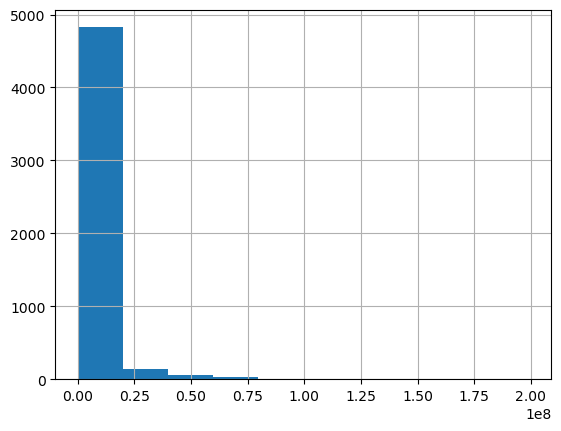

In [5]:
houses["price"].hist(bins=10)

In [6]:

bins = [0, 1_500_000, 2_600_000, 6_000_000, float("inf")]
labels = ["Économique", "Intermédiaire", "Haut de gamme", "Luxe"]
houses["price_class"] = pd.cut(houses["price"], bins=bins, labels=labels)


In [7]:
houses.head()

,title,displayAddress,bathrooms,bedrooms,addedOn,type,price,verified,priceDuration,sizeMin,furnishing,description,price_class
0,Great ROI I High Floor I Creek View,"Binghatti Canal, Business Bay, Dubai",3,2,2024-08-14T12:02:53Z,Residential for Sale,2500000,True,sell,1323 sqft,NO,MNA Properties is delighted to offer this apar...,Intermédiaire
1,Full Sea View | Beach Life | Brand New Residence,"La Vie, Jumeirah Beach Residence, Dubai",3,2,2024-08-13T05:45:16Z,Residential for Sale,7200000,True,sell,1410 sqft,YES,"Apartment for sale in La Vie, Jumeirah Beach R...",Luxe
2,Green Belt | Corner Unit | Spacious Plot,"La Rosa 6, Villanova, Dubai Land, Dubai",3,4,2024-08-14T06:24:28Z,Residential for Sale,3600000,True,sell,2324 sqft,NO,Treo Homes is very pleased to be bringing to t...,Haut de gamme
3,2BR+Study | Near Pool and Park | Private,"Springs 15, The Springs, Dubai",3,2,2024-08-15T06:07:22Z,Residential for Sale,2999999,True,sell,1647 sqft,NO,2 Bedrooms + Study | Near Pool &amp; Park | Pr...,Haut de gamme
4,Vacant | Well Maintained | Area Expert,"Noor Townhouses, Town Square, Dubai",3,3,2024-08-09T08:28:59Z,Residential for Sale,2449999,True,sell,2105 sqft,NO,-Type 1\n-3 Bed+Maid\n-Close To Amenities\n-BU...,Intermédiaire


In [8]:
from sklearn.model_selection import train_test_split
train_set,test_set=train_test_split(houses,test_size=0.2,stratify=houses["price_class"],random_state=42)

In [9]:
print(houses['type'].value_counts())

type
Residential for Sale    5058
Name: count, dtype: int64


In [10]:
def split_address(X):
    X=X.copy()
    parts=X['displayAddress'].str.split(',')
    X['building']=parts.str[0].str.strip().str.lower()
    X['community']=parts.str[-2].str.strip().str.lower()
    X['city']=parts.str[-1].str.strip().str.lower()
    return X.drop('displayAddress',axis=1)

In [11]:
def extract_year_size_min(X):
    X = X.copy()
    X["addedOn"] = pd.to_datetime(X["addedOn"], errors="coerce").dt.year
    X["sizeMin"] = pd.to_numeric(
        X["sizeMin"].astype(str).str.replace(",", "").str.split(" ").str[0],
        errors="coerce",
    )
    return X.drop('title',axis=1)

In [13]:
def binary_value(X):
    X = X.copy()
    X["verified"] = X["verified"].fillna(False).astype(bool).astype(int)
    X["furnishing"] = (
        X["furnishing"].astype(str).str.strip().str.upper()
        .map({"YES": 1, "NO": 0})
        .fillna(0)
        .astype(int)
    )
    return X

In [12]:
train_set['description'][0]

'MNA Properties is delighted to offer this apartment located in the well-esteemed Binghatti Canal, situated in the heart of Business Bay, Dubai, UAE. The 2BR apartment with the most attractive layout based on the high floor and offers the breathtaking panoramic view of Business Bay Canal; near Burj Khalifa.\n\nTo arrange a viewing or to find out more, please contact Amir via phone or Whatsapp on +971581684981 or email at amir.m@mnaproperties.ae\n\nProperty Features:\n2 Bedrooms\n2 Bathrooms + Guest room\nSize 1,323 sq. ft.\n2 Balconies\nPrivate Jacuzzi / Small Pool\nCanal View\n\nCan be sold Unfurnished as well\n\nBinghatti Canal Residences is a newly built project in Business Bay, Dubai that features symbolic design elements to generate a sense of community. Binghatti Canal reflects Binghatti Developers traditional Middle Eastern architecture and art, in addition to its modern design. Bingatti Canal finishing demonstrate the highest degree of quality and workmanship available only fro

In [15]:
def description_features(X):
    X = X.copy()
    d = X["description"].fillna("").str.lower()
    X["desc_len"] = d.str.len()
    X["desc_words"] = d.str.split().str.len()
    X["desc_has_pool"] = d.str.contains("pool").astype(int)
    X["desc_has_view"] = d.str.contains("view").astype(int)
    X["desc_has_gym"] = d.str.contains("gym|fitness").astype(int)
    X["desc_has_parking"] = d.str.contains("parking").astype(int)
    X["desc_luxury_words"] = d.str.count("luxury|exclusive|premium|prime|branded")
    return X.drop(columns=["description"])
def type_price_duration_en_0_1(X):
     X=X.copy()
     X["is_for_sale"] = (X["type"] == "Residential for Sale").astype(int)
     X["priceDuration"] = (X["priceDuration"] == "sell").astype(int)
     return X.drop(columns=["type"])
def clean_rooms(X):
    X = X.copy()
    for col in ["bedrooms", "bathrooms"]:
        s = X[col].astype(str).str.lower().str.strip()
        s = s.replace({"studio": "0"})          # studio = 0 chambre
        s = s.str.replace("+", "", regex=False)  # '7+' devient '7'
        X[col] = pd.to_numeric(s, errors="coerce")
    return X    

In [13]:
categorie=['building','community','city']
num=['bathrooms','bedrooms','addedOn','sizeMin']


In [33]:
x_train=train_set.drop(columns=["price", "price_class"])
y_train=train_set['price_class'].copy()
x_test=test_set.drop(columns=["price", "price_class"])
y_test=test_set['price_class'].copy()

In [15]:
pipeline_num=make_pipeline(SimpleImputer(strategy='median'), StandardScaler());

In [16]:
preprocessing= build_preprocessing()

In [17]:
processing=make_pipeline( build_preprocessing(),HistGradientBoostingClassifier(random_state=42))

In [18]:
print(processing)

Pipeline(steps=[('pipeline',
                 Pipeline(steps=[('functiontransformer-1',
                                  FunctionTransformer(func=<function split_address at 0x00000236C46E2D40>)),
                                 ('functiontransformer-2',
                                  FunctionTransformer(func=<function clean_rooms at 0x00000236C46E2DE0>)),
                                 ('functiontransformer-3',
                                  FunctionTransformer(func=<function extract_year_size_min at 0x00000236C46E2E80>)),
                                 ('functiontr...
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=30,
                                                                                 sparse_output=False),
                                                                   ['building',
           

In [19]:
predictions_train=cross_val_predict(processing,x_train,y_train,cv=10)

In [20]:
for c in ["bathrooms", "bedrooms", "addedOn", "sizeMin"]:
    print(c, x_train[c].dtype, x_train[c].astype(str).unique()[:15])

bathrooms object ['5' '1' '4' '2' '6' '7' '3' 'nan' '7+' 'none']
bedrooms object ['4' 'studio' '1' '2' '5' 'nan' '3' '6' '7' '7+']
addedOn object ['2024-07-12T13:06:25Z' '2024-04-23T10:16:43Z' '2024-07-17T10:46:16Z'
 '2024-08-16T12:02:55Z' '2024-07-22T09:48:22Z' '2024-07-16T12:50:00Z'
 '2024-08-14T10:54:00Z' '2024-08-19T10:34:26Z' '2024-07-27T06:46:11Z'
 '2024-07-30T12:22:19Z' '2024-07-20T09:43:05Z' '2024-06-11T07:47:44Z'
 '2024-08-14T06:42:30Z' '2024-08-14T08:34:58Z' '2024-07-20T08:38:24Z']
sizeMin object ['3262 sqft' '777 sqft' '901 sqft' '2415 sqft' '991 sqft' '506 sqft'
 '5694 sqft' '1152 sqft' '459 sqft' '890 sqft' '815 sqft' '1137 sqft'
 '858 sqft' '3014 sqft' '1475 sqft']


In [21]:
#Evaluation histgradientboostingclassifier
print(classification_report(y_train, predictions_train))
print(f1_score(y_train, predictions_train, average="macro"))

               precision    recall  f1-score   support

Haut de gamme       0.73      0.78      0.75      1094
Intermédiaire       0.68      0.62      0.65       843
         Luxe       0.87      0.81      0.84       727
   Économique       0.87      0.90      0.89      1382

     accuracy                           0.79      4046
    macro avg       0.79      0.78      0.78      4046
 weighted avg       0.79      0.79      0.79      4046

0.7815047236522352


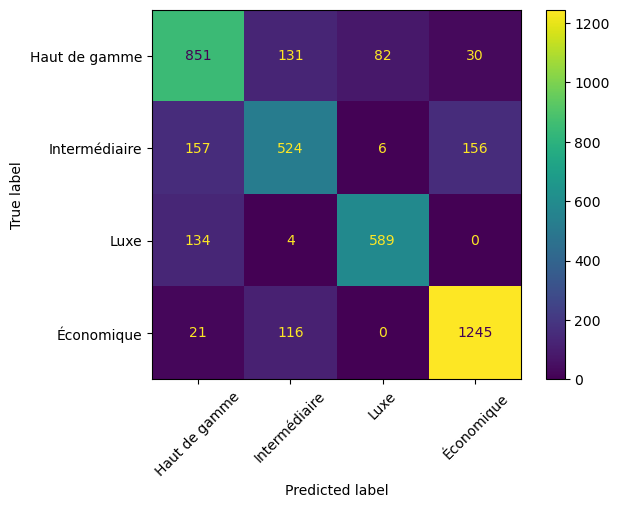

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_train, predictions_train, xticks_rotation=45)

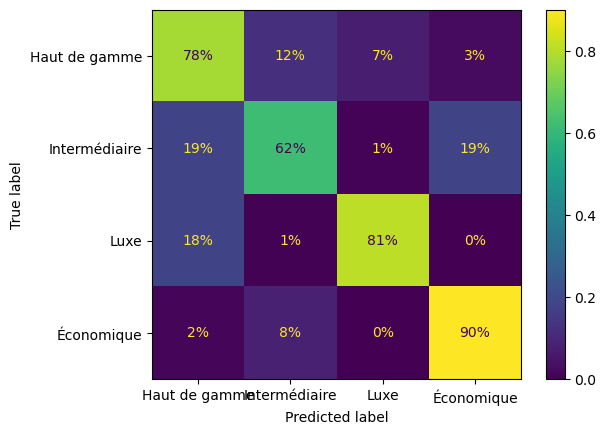

In [23]:
ConfusionMatrixDisplay.from_predictions(y_train, predictions_train,
normalize="true", 
values_format=".0%")
plt.show()

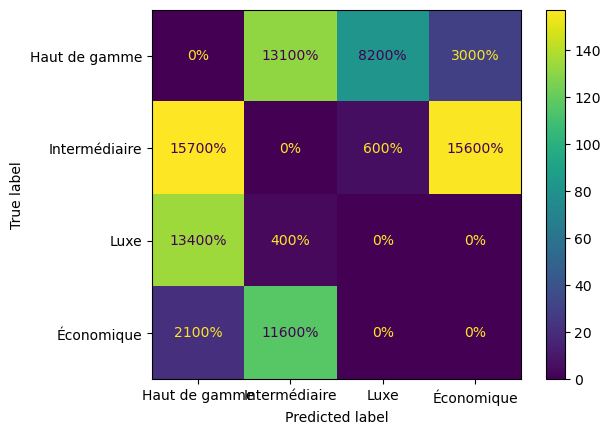

In [24]:
sample_weight = (predictions_train != y_train)
ConfusionMatrixDisplay.from_predictions(y_train, predictions_train,
sample_weight=sample_weight,
values_format="0.00%")
plt.show()

In [25]:
#on doit essayer la regression puis faire unseuil pour chaque classe

In [26]:
# pip install xgboost
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score

In [27]:
y_train_log = np.log1p(train_set["price"]) # même index que x_train

In [28]:
reg_pipe = make_pipeline(
    preprocessing,
    XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
    ),
)

In [29]:
cv = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
          .split(x_train, y_train))        # stratifié sur les classes
pred_log = cross_val_predict(reg_pipe, x_train, y_train_log, cv=cv)

In [30]:
# Qualité de la régression (en log)
print("MAE (log) :", mean_absolute_error(y_train_log, pred_log))
print("R2        :", r2_score(y_train_log, pred_log))

# Retour au prix, puis découpage avec LES MÊMES seuils que ta cible
pred_price = np.expm1(pred_log)
pred_class = pd.cut(pred_price, bins=bins, labels=labels)

print(classification_report(y_train, pred_class))
print("macro-F1 :", f1_score(y_train, pred_class, average="macro"))

MAE (log) : 0.24976729872480943
R2        : 0.8862578285365406
               precision    recall  f1-score   support

Haut de gamme       0.72      0.76      0.74      1094
Intermédiaire       0.61      0.61      0.61       843
         Luxe       0.86      0.82      0.84       727
   Économique       0.88      0.86      0.87      1382

     accuracy                           0.78      4046
    macro avg       0.77      0.76      0.77      4046
 weighted avg       0.78      0.78      0.78      4046

macro-F1 : 0.7656003563054226


In [31]:
rf_clf_pipe = make_pipeline(
    preprocessing,
    RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
)

pred_rf = cross_val_predict(rf_clf_pipe, x_train, y_train, cv=cv)

print(classification_report(y_train, pred_rf))
print("macro-F1 :", f1_score(y_train, pred_rf, average="macro"))

               precision    recall  f1-score   support

Haut de gamme       0.69      0.79      0.74      1094
Intermédiaire       0.67      0.52      0.58       843
         Luxe       0.86      0.77      0.82       727
   Économique       0.83      0.90      0.87      1382

     accuracy                           0.77      4046
    macro avg       0.77      0.75      0.75      4046
 weighted avg       0.77      0.77      0.76      4046

macro-F1 : 0.7515064376361211


In [32]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, loguniform, uniform

hgb_pipe = make_pipeline(
     build_preprocessing(),
    HistGradientBoostingClassifier(early_stopping=True,random_state=42,validation_fraction=0.1, n_iter_no_change=15),
)

param_dist = {
    "histgradientboostingclassifier__learning_rate":     loguniform(0.02, 0.3),
    "histgradientboostingclassifier__max_iter":          randint(150, 800),
    "histgradientboostingclassifier__max_leaf_nodes":    randint(8, 64),
    "histgradientboostingclassifier__max_depth":         [None, 4, 6, 8, 10],
    "histgradientboostingclassifier__min_samples_leaf":  randint(10, 80),
    "histgradientboostingclassifier__l2_regularization": loguniform(1e-3, 10),
    "histgradientboostingclassifier__class_weight":      [None, "balanced"],
}

search_hgb = RandomizedSearchCV(
    hgb_pipe,
    param_distributions=param_dist,
    n_iter=20,
    scoring="f1_macro",
    cv=cv,                 # mêmes folds que tes autres modèles
    random_state=42,
    n_jobs=1,              # HGB est déjà multithreadé
    verbose=1,
    refit=True,
)
search_hgb.fit(x_train, y_train)

print("Meilleur macro-F1 (CV) :", search_hgb.best_score_)
print(search_hgb.best_params_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Meilleur macro-F1 (CV) : 0.7662660244734711
{'histgradientboostingclassifier__class_weight': 'balanced', 'histgradientboostingclassifier__l2_regularization': 0.0011384639705304643, 'histgradientboostingclassifier__learning_rate': 0.03426784619982225, 'histgradientboostingclassifier__max_depth': 6, 'histgradientboostingclassifier__max_iter': 568, 'histgradientboostingclassifier__max_leaf_nodes': 40, 'histgradientboostingclassifier__min_samples_leaf': 14}


               precision    recall  f1-score   support

Haut de gamme       0.76      0.76      0.76       273
Intermédiaire       0.69      0.69      0.69       211
         Luxe       0.82      0.85      0.83       182
   Économique       0.91      0.89      0.90       346

     accuracy                           0.81      1012
    macro avg       0.79      0.80      0.80      1012
 weighted avg       0.81      0.81      0.81      1012

macro-F1 test : 0.795819664229837


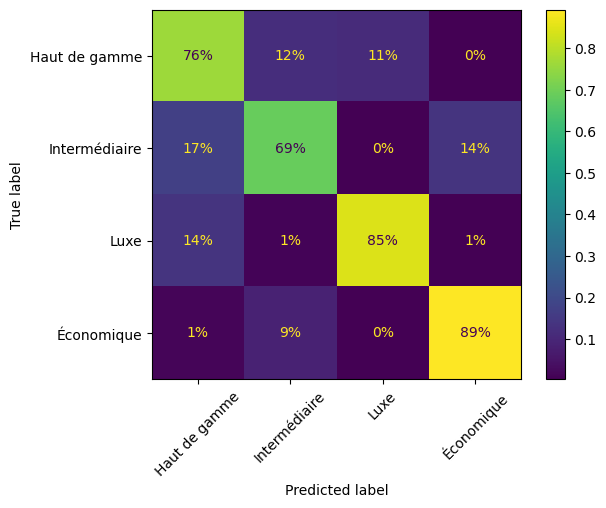

In [34]:
final_model = search_hgb.best_estimator_      # si le tuné est meilleur
# final_model = make_pipeline(build_preprocessing(), HistGradientBoostingClassifier(random_state=42))  # si le défaut est meilleur

# Le défaut n'est pas entraîné, donc on fit sur tout le train (sans effet sur best_estimator_, déjà réentraîné)
final_model.fit(x_train, y_train)

# Évaluation finale : UNE seule fois
pred_test = final_model.predict(x_test)

print(classification_report(y_test, pred_test))
print("macro-F1 test :", f1_score(y_test, pred_test, average="macro"))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, normalize="true", values_format=".0%", xticks_rotation=45
)
plt.show()

In [35]:
(root / "models").mkdir(exist_ok=True)
joblib.dump(final_model, root / "models" / "model.joblib")

['c:\\Users\\user\\Desktop\\models_AI\\Houses_dubai_classifier\\models\\model.joblib']